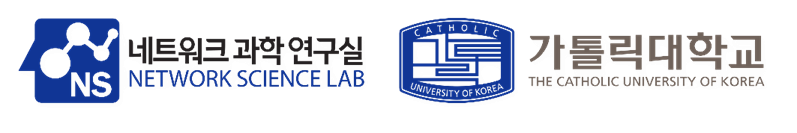

# Week 13: GNNs for Recommendation Systems and Molecular Structure Learning

<a target="_blank" href="https://colab.research.google.com/github/NSLab-CUK/Graph-Neural-Networks-Fall-2026/blob/main/W13/SampleCode_13.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

### The idea in two sentences

* A **molecule is a graph**: atoms are nodes, chemical bonds are edges. A GNN can read it and predict a property (e.g. solubility).
* A **recommender is a graph** too: users and items are nodes, a "like" is an edge. A GNN spreads taste along the edges and predicts the missing ones.

## 1. Setup

In [1]:
# @title Install (only needed on Colab)
import sys
if "google.colab" in sys.modules:
    !pip install -q rdkit py3Dmol torch_geometric

In [2]:
# @title Imports and colors
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import py3Dmol

from rdkit import Chem
from rdkit.Chem import AllChem, Draw, Descriptors

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.utils import from_smiles

SEED = 42
torch.manual_seed(SEED)

# Usual chemistry colors (CPK): carbon gray, oxygen red, nitrogen blue, hydrogen white.
ATOM_COLORS = {"C": "#5b5b5b", "O": "#e0312b", "N": "#2a78d6", "H": "#e8e8e8", "S": "#e6b800", "Cl": "#2fa84f"}
COLORS = {"user": "#2a78d6", "item": "#eb6834", "like": "#9a9a9a", "rec": "#2fa84f"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "figure.dpi": 110})

# Part A: Molecules

## 2. SMILES: a molecule written as text

**SMILES** writes a molecule as one line of text. Five rules cover most cases:

| Rule | Example | Meaning |
|---|---|---|
| Atoms are letters, hydrogens are implicit | `CCO` | C–C–O = ethanol |
| `=` double bond, `#` triple bond | `C=O`, `C#N` | formaldehyde, a nitrile |
| `( )` opens a branch | `CC(=O)O` | acetic acid |
| Same digit = ring closure | `C1CCCCC1` | cyclohexane |
| Lowercase = aromatic atom | `c1ccccc1` | benzene |

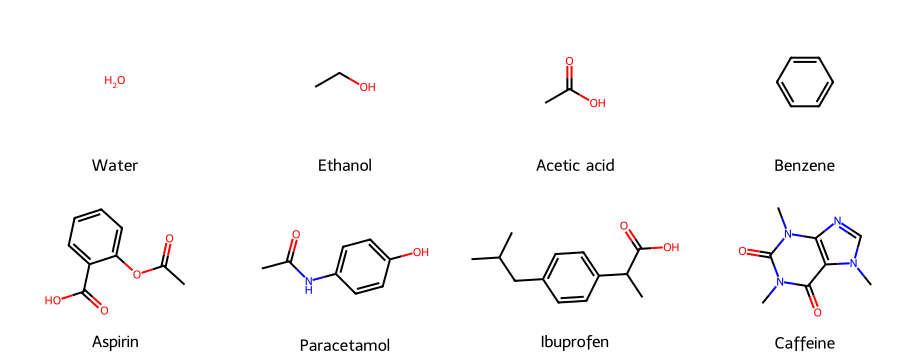

In [3]:
MOLECULES = {
    "Water":       "O",
    "Ethanol":     "CCO",
    "Acetic acid": "CC(=O)O",
    "Benzene":     "c1ccccc1",
    "Aspirin":     "CC(=O)Oc1ccccc1C(=O)O",
    "Paracetamol": "CC(=O)Nc1ccc(O)cc1",
    "Ibuprofen":   "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
    "Caffeine":    "CN1C=NC2=C1C(=O)N(C(=O)N2C)C",
}
mols = {name: Chem.MolFromSmiles(s) for name, s in MOLECULES.items()}   # text -> RDKit molecule

Draw.MolsToGridImage(list(mols.values()), legends=list(mols), molsPerRow=4, subImgSize=(230, 180))

RDKit computes simple facts straight from the SMILES string:

In [4]:
pd.DataFrame([{"name": name,
               "SMILES": MOLECULES[name],
               "formula": Chem.rdMolDescriptors.CalcMolFormula(m),
               "atoms (no H)": m.GetNumAtoms(),
               "bonds": m.GetNumBonds(),
               "weight (g/mol)": round(Descriptors.MolWt(m), 1)} for name, m in mols.items()])

,name,SMILES,formula,atoms (no H),bonds,weight (g/mol)
0,Water,O,H2O,1,0,18.0
1,Ethanol,CCO,C2H6O,3,2,46.1
2,Acetic acid,CC(=O)O,C2H4O2,4,3,60.1
3,Benzene,c1ccccc1,C6H6,6,6,78.1
4,Aspirin,CC(=O)Oc1ccccc1C(=O)O,C9H8O4,13,13,180.2
5,Paracetamol,CC(=O)Nc1ccc(O)cc1,C8H9NO2,11,11,151.2
6,Ibuprofen,CC(C)Cc1ccc(cc1)C(C)C(=O)O,C13H18O2,15,15,206.3
7,Caffeine,CN1C=NC2=C1C(=O)N(C(=O)N2C)C,C8H10N4O2,14,15,194.2


One molecule can be written in many ways. The **canonical SMILES** is a unique name, useful to find duplicates:

In [5]:
for s in ["CCO", "OCC", "C(O)C", "[CH3][CH2][OH]"]:
    print(f"{s:16s} -> {Chem.MolToSmiles(Chem.MolFromSmiles(s))}")

CCO              -> CCO
OCC              -> CCO
C(O)C            -> CCO
[CH3][CH2][OH]   -> CCO


## 3. From SMILES to a graph

Atoms become **nodes**, bonds become **edges**. `from_smiles` (PyTorch Geometric) does it in one line:

* `x`: one row per atom, 9 numbers (atomic number, degree, charge, aromatic, ...)
* `edge_index`: the bonds, stored **twice** (i→j and j→i)
* `edge_attr`: bond type (single, double, aromatic, ...)

In [6]:
data = from_smiles(MOLECULES["Caffeine"])
print(data)
print("first 3 atoms (atomic number first):\n", data.x[:3])

Data(x=[14, 9], edge_index=[2, 30], edge_attr=[30, 3], smiles='CN1C=NC2=C1C(=O)N(C(=O)N2C)C')
first 3 atoms (atomic number first):
 tensor([[6, 0, 4, 5, 3, 0, 4, 0, 0],
        [7, 0, 3, 5, 0, 0, 3, 1, 1],
        [6, 0, 3, 5, 1, 0, 3, 1, 1]])


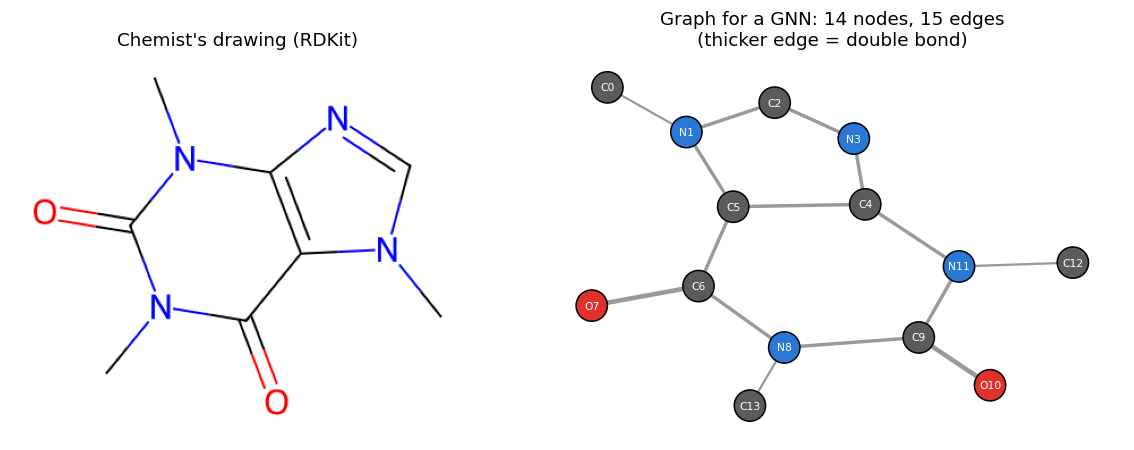

In [7]:
# @title Plot: the chemist's drawing vs the graph a GNN sees
mol = mols["Caffeine"]
G = nx.Graph()
for atom in mol.GetAtoms():
    G.add_node(atom.GetIdx(), symbol=atom.GetSymbol())
for bond in mol.GetBonds():
    G.add_edge(bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(), order=bond.GetBondTypeAsDouble())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.imshow(Draw.MolToImage(mol, size=(400, 340))); ax1.axis("off"); ax1.set_title("Chemist's drawing (RDKit)")

pos = nx.spring_layout(G, seed=1, iterations=500)
symbols = nx.get_node_attributes(G, "symbol")
nx.draw_networkx_edges(G, pos, ax=ax2, width=[1.5 * G[u][v]["order"] for u, v in G.edges], edge_color="#9a9a9a")
nx.draw_networkx_nodes(G, pos, ax=ax2, node_size=420, edgecolors="black",
                       node_color=[ATOM_COLORS[symbols[n]] for n in G])
nx.draw_networkx_labels(G, pos, ax=ax2, labels={n: f"{symbols[n]}{n}" for n in G}, font_size=7, font_color="white")
ax2.set_title(f"Graph for a GNN: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges\n(thicker edge = double bond)")
ax2.axis("off")
plt.tight_layout(); plt.show()

## 4. Molecules in 3D

Real molecules have a shape. RDKit can guess one from the SMILES:

1. `AddHs`: add the hidden hydrogens back,
2. `EmbedMolecule`: guess 3D coordinates (ETKDG method),
3. `MMFFOptimizeMolecule`: relax the shape with a force field.

**Drag to rotate, scroll to zoom.**

In [8]:
def to_3d(smiles):
    mol = Chem.AddHs(Chem.MolFromSmiles(smiles))
    AllChem.EmbedMolecule(mol, randomSeed=SEED)
    AllChem.MMFFOptimizeMolecule(mol)
    return mol

STYLES = {"stick":          {"stick": {}},
          "ball and stick": {"stick": {"radius": 0.15}, "sphere": {"scale": 0.25}},
          "space filling":  {"sphere": {}}}

caffeine_3d = to_3d(MOLECULES["Caffeine"])
view = py3Dmol.view(width=900, height=300, viewergrid=(1, 3))
for col, (name, style) in enumerate(STYLES.items()):
    view.addModel(Chem.MolToMolBlock(caffeine_3d), "mol", viewer=(0, col))
    view.setStyle(style, viewer=(0, col))
    view.addLabel(name, {"position": {"x": 0, "y": 4.5, "z": 0}, "fontSize": 13}, viewer=(0, col))
view.setBackgroundColor("white")
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

A gallery of the other molecules (they spin slowly):

In [9]:
names = ["Ethanol", "Benzene", "Aspirin", "Paracetamol", "Ibuprofen", "Acetic acid"]
view = py3Dmol.view(width=900, height=520, viewergrid=(2, 3))
for k, name in enumerate(names):
    cell = (k // 3, k % 3)
    view.addModel(Chem.MolToMolBlock(to_3d(MOLECULES[name])), "mol", viewer=cell)
    view.setStyle(STYLES["ball and stick"], viewer=cell)
    view.addLabel(name, {"position": {"x": 0, "y": 5, "z": 0}, "fontSize": 13}, viewer=cell)
view.zoomTo()
view.spin(True)
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

For a **3D GNN** (SchNet, DimeNet, EGNN) the input is the same graph plus one extra tensor: the **position of every atom**, `pos` of shape `[atoms, 3]`. Here is exactly that data, drawn with matplotlib:

pos shape: (24, 3)


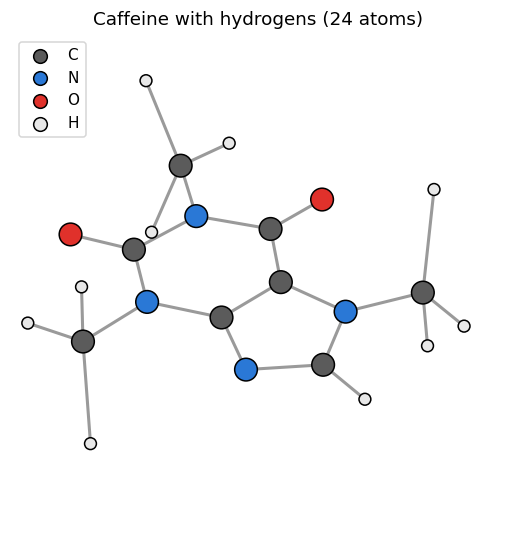

In [10]:
# @title Plot: the 3D graph (atoms = nodes with positions, bonds = edges)
pos3d = caffeine_3d.GetConformer().GetPositions()          # [atoms, 3] in Ångström
symbols = [a.GetSymbol() for a in caffeine_3d.GetAtoms()]
print("pos shape:", pos3d.shape)

fig = plt.figure(figsize=(6.5, 4.5))
ax = fig.add_subplot(projection="3d")
for b in caffeine_3d.GetBonds():
    i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
    ax.plot(*pos3d[[i, j]].T, color="#9a9a9a", lw=2)
ax.scatter(*pos3d.T, s=[60 if s == "H" else 220 for s in symbols],
           c=[ATOM_COLORS[s] for s in symbols], edgecolors="black", depthshade=False)
for s in ["C", "N", "O", "H"]:
    ax.scatter([], [], c=ATOM_COLORS[s], edgecolors="black", s=80, label=s)
ax.legend(loc="upper left"); ax.set_title("Caffeine with hydrogens (24 atoms)")
ax.set_box_aspect(np.ptp(pos3d, axis=0) + [0, 0, 2], zoom=1.35); ax.set_axis_off(); ax.view_init(elev=35, azim=-70)
plt.subplots_adjust(0, 0, 1, 1)
plt.show()

## 5. A small GNN: predict solubility from SMILES

**ESOL** has 1,128 molecules (SMILES) with their measured water solubility (log mol/L). The model:

1. each atom starts as a learned vector for its element,
2. 3 rounds of **message passing** (GIN layers): every atom collects its neighbors,
3. **sum** the atom vectors into one molecule vector, then a linear layer gives the solubility.

In [11]:
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINConv, global_add_pool

dataset = MoleculeNet("data", "ESOL").shuffle()
train_set, test_set = dataset[:900], dataset[900:]
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
print(dataset, "| example:", dataset[0].smiles.strip(), "-> y =", dataset[0].y.item())

class MolGNN(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.atom_emb = nn.Embedding(120, hidden)                     # one vector per element
        self.convs = nn.ModuleList([GINConv(nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(),
                                                          nn.Linear(hidden, hidden))) for _ in range(3)])
        self.head = nn.Linear(hidden, 1)

    def forward(self, data):
        h = self.atom_emb(data.x[:, 0])                               # x[:, 0] = atomic number
        for conv in self.convs:
            h = F.relu(conv(h, data.edge_index))                      # message passing
        return self.head(global_add_pool(h, data.batch)).squeeze(-1)  # atoms -> molecule

model = MolGNN()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
for epoch in range(1, 101):
    for batch in train_loader:
        optimizer.zero_grad()
        loss = F.mse_loss(model(batch), batch.y.squeeze(-1))
        loss.backward()
        optimizer.step()
    if epoch % 25 == 0:
        print(f"epoch {epoch:3d} | train MSE {loss.item():.3f}")

ESOL(1128) | example: CCCCc1c(C)nc(nc1O)N(C)C -> y = -2.240000009536743


epoch  25 | train MSE 6.011


epoch  50 | train MSE 0.193


epoch  75 | train MSE 0.381


epoch 100 | train MSE 0.822


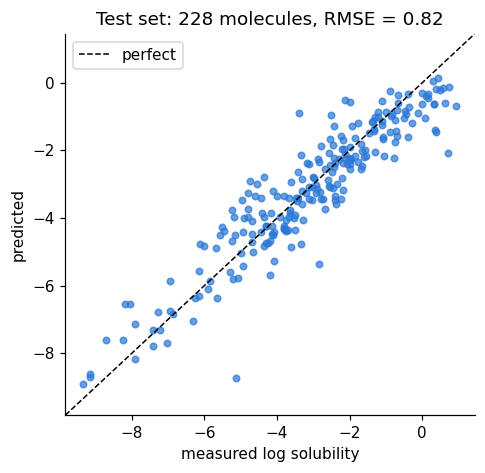

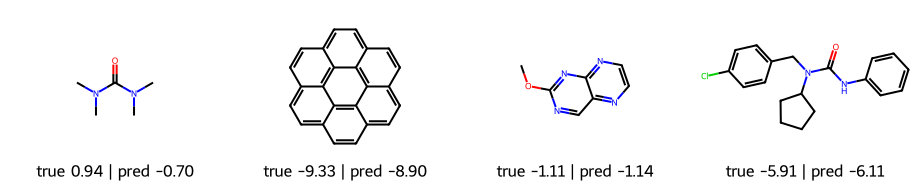

In [12]:
# @title Plot: predicted vs measured solubility on unseen molecules
model.eval()
with torch.no_grad():
    test_batch = next(iter(DataLoader(test_set, batch_size=len(test_set))))
    pred, true = model(test_batch).numpy(), test_batch.y.squeeze(-1).numpy()
rmse = np.sqrt(np.mean((pred - true) ** 2))

fig, ax = plt.subplots(figsize=(4.8, 4.5))
ax.scatter(true, pred, s=18, alpha=0.7, color=COLORS["user"])
lim = [true.min() - 0.5, true.max() + 0.5]
ax.plot(lim, lim, "--", color="black", lw=1, label="perfect")
ax.set(xlim=lim, ylim=lim, xlabel="measured log solubility", ylabel="predicted",
       title=f"Test set: {len(true)} molecules, RMSE = {rmse:.2f}")
ax.legend(); plt.show()

idx = [int(np.argmax(true)), int(np.argmin(true)), 0, 1]        # most soluble, least soluble, two others
Draw.MolsToGridImage([Chem.MolFromSmiles(test_set[i].smiles.strip()) for i in idx], molsPerRow=4, subImgSize=(230, 190),
                     legends=[f"true {true[i]:.2f} | pred {pred[i]:.2f}" for i in idx])

# Part B: Recommender system

## 6. Users and movies as a bipartite graph

7 users, 8 movies. An edge = "this user liked this movie". Two taste groups (sci-fi and romance), and Grace likes both.

In [13]:
USERS  = ["Alice", "Bob", "Chloe", "Dan", "Emma", "Finn", "Grace"]
MOVIES = ["Star Wars", "The Matrix", "Alien", "Interstellar",          # sci-fi
          "Titanic", "The Notebook", "La La Land", "Amélie"]           # romance
LIKES = {"Alice": ["Star Wars", "The Matrix", "Alien"],
         "Bob":   ["Star Wars", "The Matrix", "Interstellar"],
         "Chloe": ["The Matrix", "Alien"],
         "Dan":   ["Titanic", "The Notebook", "La La Land"],
         "Emma":  ["Titanic", "La La Land", "Amélie"],
         "Finn":  ["The Notebook", "Amélie"],
         "Grace": ["Interstellar", "La La Land"]}

U, I = len(USERS), len(MOVIES)
pairs = torch.tensor([[USERS.index(u), MOVIES.index(m)] for u, ms in LIKES.items() for m in ms]).T   # [2, likes]
liked = torch.zeros(U, I, dtype=torch.bool)
liked[pairs[0], pairs[1]] = True

# One graph with U + I nodes: users are 0..U-1, movies are U..U+I-1. Edges in both directions.
edge_index = torch.cat([torch.stack([pairs[0], pairs[1] + U]), torch.stack([pairs[1] + U, pairs[0]])], dim=1)
print(f"{U} users, {I} movies, {pairs.shape[1]} likes -> edge_index {tuple(edge_index.shape)}")

7 users, 8 movies, 18 likes -> edge_index (2, 36)


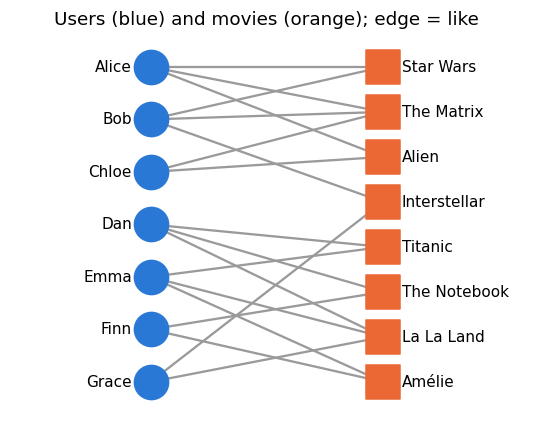

In [14]:
# @title Plot: the user-movie graph
def draw_bipartite(ax, recs=None, title=""):
    B = nx.Graph()
    B.add_nodes_from(USERS); B.add_nodes_from(MOVIES)
    B.add_edges_from((u, m) for u, ms in LIKES.items() for m in ms)
    pos = {u: (0, -k) for k, u in enumerate(USERS)}
    pos.update({m: (1, -k * (U - 1) / (I - 1)) for k, m in enumerate(MOVIES)})
    nx.draw_networkx_edges(B, pos, ax=ax, edge_color=COLORS["like"], width=1.5)
    if recs:
        nx.draw_networkx_edges(nx.Graph(recs), pos, ax=ax, edge_color=COLORS["rec"], width=2.5, style="--")
    nx.draw_networkx_nodes(B, pos, nodelist=USERS, node_color=COLORS["user"], node_size=500, ax=ax)
    nx.draw_networkx_nodes(B, pos, nodelist=MOVIES, node_color=COLORS["item"], node_shape="s", node_size=500, ax=ax)
    for n, (x, y) in pos.items():
        ax.text(x - 0.08 if x == 0 else x + 0.08, y, n, ha="right" if x == 0 else "left", va="center")
    ax.set_xlim(-0.6, 1.6); ax.set_title(title); ax.axis("off")

fig, ax = plt.subplots(figsize=(6, 4.5))
draw_bipartite(ax, title="Users (blue) and movies (orange); edge = like")
plt.show()

## 7. LightGCN

**LightGCN** gives every user and movie an embedding vector, then smooths it over the graph: each node's new vector is the (normalized) average of its neighbors, repeated $K$ times. No weights, no activation, just propagation.

The score of user $u$ for movie $i$ is a dot product: $\hat{y}_{ui} = \mathbf{e}_u \cdot \mathbf{e}_i$.

**BPR loss:** a movie the user liked must score higher than a random movie they did not like.

In [15]:
from torch_geometric.nn import LightGCN

torch.manual_seed(SEED)
rec_model = LightGCN(num_nodes=U + I, embedding_dim=16, num_layers=2)
optimizer = torch.optim.Adam(rec_model.parameters(), lr=0.01)

for epoch in range(1, 301):
    neg_items = torch.randint(0, I, (pairs.shape[1],))                    # one random movie per like
    pos_edges = torch.stack([pairs[0], pairs[1] + U])
    neg_edges = torch.stack([pairs[0], neg_items + U])
    pos_score = rec_model(edge_index, pos_edges)
    neg_score = rec_model(edge_index, neg_edges)
    loss = rec_model.recommendation_loss(pos_score, neg_score)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    if epoch % 100 == 0:
        print(f"epoch {epoch:3d} | BPR loss {loss.item():.3f}")

epoch 100 | BPR loss 0.422
epoch 200 | BPR loss 0.198


epoch 300 | BPR loss 0.232


## 8. Recommendations

Score every (user, movie) pair, hide the movies already liked, recommend the best one.

In [16]:
with torch.no_grad():
    emb = rec_model.get_embedding(edge_index)
    scores = emb[:U] @ emb[U:].T                                           # [users, movies]

new_scores = scores.masked_fill(liked, -float("inf"))                    # only movies not seen yet
best = new_scores.argmax(1)
recs = [(USERS[u], MOVIES[best[u]]) for u in range(U)]
for u, m in recs:
    print(f"{u:6s} liked {', '.join(LIKES[u]):40s} -> recommend: {m}")

Alice  liked Star Wars, The Matrix, Alien             -> recommend: Interstellar
Bob    liked Star Wars, The Matrix, Interstellar      -> recommend: Alien
Chloe  liked The Matrix, Alien                        -> recommend: Star Wars
Dan    liked Titanic, The Notebook, La La Land        -> recommend: Amélie
Emma   liked Titanic, La La Land, Amélie              -> recommend: The Notebook
Finn   liked The Notebook, Amélie                     -> recommend: Titanic
Grace  liked Interstellar, La La Land                 -> recommend: Titanic


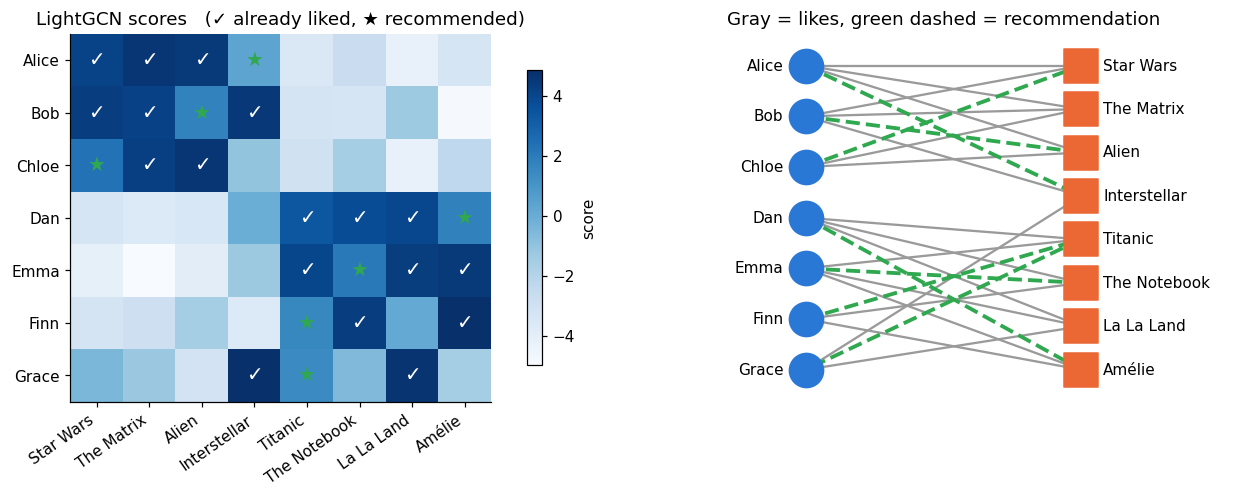

In [17]:
# @title Plot: score matrix, and the recommendations on the graph
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})

im = ax1.imshow(scores, cmap="Blues")
ax1.set_xticks(range(I), MOVIES, rotation=35, ha="right"); ax1.set_yticks(range(U), USERS)
for u in range(U):
    for i in range(I):
        mark = "✓" if liked[u, i] else ("★" if i == best[u] else "")
        ax1.text(i, u, mark, ha="center", va="center", fontsize=13,
                 color="white" if liked[u, i] else COLORS["rec"], fontweight="bold")
ax1.grid(False); fig.colorbar(im, ax=ax1, shrink=0.8, label="score")
ax1.set_title("LightGCN scores   (✓ already liked, ★ recommended)")

draw_bipartite(ax2, recs=recs, title="Gray = likes, green dashed = recommendation")
plt.tight_layout(); plt.show()

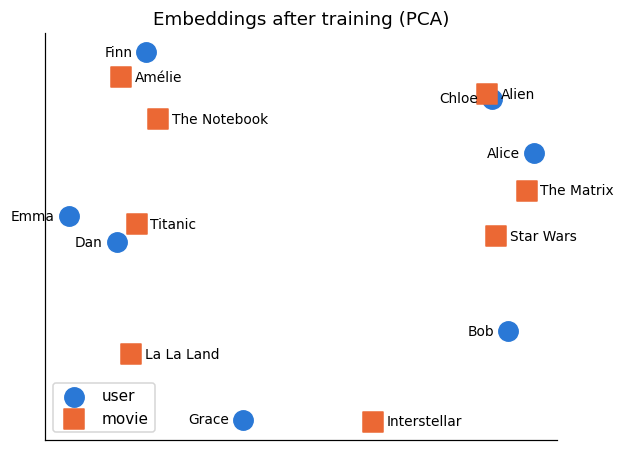

In [18]:
# @title Plot: users and movies share one embedding space
xy = emb - emb.mean(0)
xy = (xy @ torch.linalg.svd(xy, full_matrices=False).Vh[:2].T).numpy()    # PCA to 2D

fig, ax = plt.subplots(figsize=(6, 4.8))
ax.scatter(*xy[:U].T, s=160, color=COLORS["user"], label="user")
ax.scatter(*xy[U:].T, s=160, color=COLORS["item"], marker="s", label="movie")
for k, name in enumerate(USERS + MOVIES):
    is_user = k < U                                                       # users labeled left, movies right
    ax.annotate(name, xy[k], xytext=(-9 if is_user else 9, 0), textcoords="offset points",
                ha="right" if is_user else "left", va="center", fontsize=9)
ax.set(xticks=[], yticks=[], title="Embeddings after training (PCA)")
ax.legend(); plt.show()

Users land next to the movies they like, and the two taste groups separate. Grace, who likes one movie from each group, sits **in between**.

**References**

* Weininger. *SMILES, a chemical language and information system.* J. Chem. Inf. Comput. Sci. 1988.
* Delaney. *ESOL: Estimating aqueous solubility directly from molecular structure.* J. Chem. Inf. Comput. Sci. 2004.
* Xu, Hu, Leskovec, Jegelka. *How Powerful are Graph Neural Networks?* ICLR 2019 (GIN).
* He et al. *LightGCN: Simplifying and Powering Graph Convolution Network for Recommendation.* SIGIR 2020.